# 12 · Multiphase fluids with the fully implicit OBL solver

Four fully implicit (FIM) runs on the same small layered block model used by the 3D doublet animation in the
README (`block_model.py` next to this notebook; no external data):

1. dead-oil water injection (water–oil),
2. gas injection into a black oil while the producer depletes the field (oil–gas, three components),
3. CO2 injection into brine (CO2–brine, isothermal, 50 °C, 1 mol/kg NaCl),
4. cold CO2 injection, 25 °C CO2 into a 60 °C aquifer (CO2–brine with the energy equation).

The solver uses operator-based linearization (OBL; Voskov 2017, *J. Comput. Phys.* 337; Khait & Voskov 2017,
*J. Pet. Sci. Eng.* 157), two-point flux finite volumes, Newton on all unknowns, and Peaceman wells
(Peaceman 1983, *SPE J.* 23(3)). CO2 solubility is from Spycher & Pruess 2005 (*Geochim. Cosmochim. Acta* 69(13)).
Method notes: `docs/multiphase_fim.md`. Every number and figure below comes from the compiled solver run in this notebook.

**Setup, common to all four cases**

- Grid: a 10 × 10 × 12 block (1200 cells of 500 × 500 × 5 m) in four units of three layers, each unit with one
  porosity and permeability (kv/kh = 0.1). The units, pore volume and median permeability are printed in the
  setup tables below.
- Gravity on (9.80665 m/s²).
- Wells: injector INJ at column (i, j) = (5, 5) and producer PROD at (2, 2), both open in all 12 layers
  (Peaceman well index, radius 0.1 m).
- Injection: 0.008 m³/s at reservoir conditions for 40 years; results reported every 2 years.
- Solver: fully implicit Newton with operator-based linearization (OBL). **Experimental**: not validated against
  open-DARTS or OpenGeoSys on this grid.

## Setup

In [1]:
import os, time
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
from subsurfix import _native as nat
from subsurfix.viz3d import RegularGrid, Well, animate_grid
OUT = Path(os.environ.get("SX_EXAMPLE_OUT", "outputs")).resolve()
OUT.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 80, "savefig.dpi": 110})
def save(fig, name):
    fig.savefig(OUT / name, bbox_inches="tight")

## Block model
Built in code by `layered_block()`; injector INJ at column (5, 5) and producer PROD at (2, 2), both open in all
12 layers. Everything after this cell only uses `model`, `phi`, `k_md`, `cell` and the well helper, so another
property model can be swapped in here.

In [2]:
from IPython.display import Markdown, display
from block_model import column_wells, describe, layered_block
bm = layered_block()
NX, NY, NZ = bm["dims"]; cell = bm["cell"]; origin = bm["origin"]
phi, k_md = bm["phi"], bm["k_md"]
INJ, PROD = (5, 5), (2, 2)
N = phi.size
model = nat.FlowModel.from_regular(list(origin), list(cell), [NX, NY, NZ], bm["perm"], phi)
display(Markdown(describe(bm)))
PV = model.pore_volume()
def wells(q_inj, bhp_prod):
    return column_wells(bm, INJ, PROD, rate=q_inj, bhp=bhp_prod)
YR = 3.15576e7
TIMES = [0.0] + [y * YR for y in range(2, 41, 2)]
YEARS = np.array(TIMES) / YR
G = 9.80665
print(f"{N} cells, cell {cell[0]:.0f} x {cell[1]:.0f} x {cell[2]:.1f} m, pore volume {PV.sum():.3e} m3")
print(f"median k {np.median(k_md):.1f} mD (range {k_md.min():.2f}-{k_md.max():.0f}), porosity {phi.min():.3f}-{phi.max():.3f}")
display(Markdown(
    "| Setup | Value (from this run) |\n|---|---|\n"
    f"| Cells | {NX} × {NY} × {NZ} = {N} |\n"
    f"| Cell size | {cell[0]:.0f} × {cell[1]:.0f} × {cell[2]:.1f} m |\n"
    f"| Pore volume | {PV.sum():.3e} m³ |\n"
    f"| Median permeability | {np.median(k_md):.1f} mD |\n"
    f"| Injection | 0.008 m³/s for {YEARS[-1]:.0f} years = {0.008 * TIMES[-1] / PV.sum() * 100:.1f} % of the pore volume |\n"
    f"| Report times | every {YEARS[1]:.0f} years |"))

| Unit | Layers | Porosity | k (mD) |
|---|---|---|---|
| upper sand | 0–2 | 0.12 | 5 |
| main sand | 3–5 | 0.22 | 80 |
| shaly baffle | 6–8 | 0.06 | 0.5 |
| lower sand | 9–11 | 0.16 | 20 |

1200 cells, cell 500 x 500 x 5.0 m, pore volume 2.100e+08 m3
median k 12.5 mD (range 0.50-80), porosity 0.060-0.220


| Setup | Value (from this run) |
|---|---|
| Cells | 10 × 10 × 12 = 1200 |
| Cell size | 500 × 500 × 5.0 m |
| Pore volume | 2.100e+08 m³ |
| Median permeability | 12.5 mD |
| Injection | 0.008 m³/s for 40 years = 4.8 % of the pore volume |
| Report times | every 2 years |

Injection rates are reservoir volume rates. With unit permeabilities of 0.5–80 mD and 500 m cells, 0.008 m³/s
(about 690 m³/day) keeps the injector pressure inside the OBL table range (5–50 MPa). Over 40 years that is
about 5 % of the block pore volume (see the setup table), so the injected phase stays within a few cells of INJ.

## Case 1 · Dead-oil water injection
Water (1000 kg/m³, 1 mPa·s) displaces dead oil (850 kg/m³, 2 mPa·s), Corey relative permeability, gravity on.
Initial water saturation 0.2, pressure 20 MPa. Producer at 12 MPa bottom-hole pressure.

What to look for: a water bank spreading from INJ, faster in the high-permeability layers, with the injector
pressure rising until the injected volume is balanced by production.

In [3]:
runs, RUNTIME = {}, {}
t = time.time()
runs["water-oil"] = nat.run_fim_water_oil(
    model, wells(0.008, 1.2e7), np.full(N, 0.2), np.full(N, 2e7), TIMES,
    corey={"mu_o": 2e-3}, physics={"gravity": G, "rho_o": 850.0, "c_w": 4e-10, "c_o": 1e-9},
    p_range=(5e6, 5e7), table_points=(31, 201), dt_init=86400.0, dt_max=0.25 * YR)
RUNTIME["water-oil"] = time.time() - t
print(f"water-oil: {RUNTIME['water-oil']:.0f} s")

water-oil: 8 s


## Case 2 · Gas injection into a black oil
Three components (gas, oil, water) with dissolved gas (Rs), from a PVT table. Initially the oil is saturated
at 20 MPa (no free gas), water saturation 0.2. INJ injects gas, PROD produces at 10 MPa, below the bubble point,
so gas also comes out of solution near PROD.

What to look for: free gas near INJ (injected) and near PROD (exsolved as the pressure there drops below the
bubble point). The plume cell count later in the notebook includes both.

In [4]:
p_tab = 1e5 + 3e6 * np.arange(11); f = (p_tab - 1e5) / 3e7
pvt = np.column_stack([p_tab, 1 + 150 * f, 1.05 + 0.35 * f, 2e-3 - 1.2e-3 * f, 1 / (1 + 300 * f), 1.2e-5 + 1.3e-5 * f])
# columns: p (Pa), Rs (sm3/sm3), Bo, mu_o (Pa s), Bg, mu_g (Pa s)
p0 = 2e7
rs = np.interp(p0, pvt[:, 0], pvt[:, 1]); bo = np.interp(p0, pvt[:, 0], pvt[:, 2])
rho_sc = (0.9, 850.0, 1020.0)  # default surface densities (gas, oil, water)
rs_mass = rs * rho_sc[0] / rho_sc[1]
oil_mass = 0.8 * (rho_sc[1] + rs * rho_sc[0]) / bo             # live oil mass per pore volume
water_mass = 0.2 * rho_sc[2] / 1.01 * (1 + 4e-10 * (p0 - 1e5))
zo0 = oil_mass / (1 + rs_mass) / (oil_mass + water_mass)
zg0 = 0.999 * zo0 * rs_mass                                    # just below saturation: no free gas at t = 0
t = time.time()
runs["oil-gas"] = nat.run_fim_black_oil(
    model, wells(0.008, 1.0e7), np.full(N, p0), np.full(N, zg0), np.full(N, zo0), TIMES,
    pvt=pvt, bw=1.01, gravity=G, injection=[(1.0, 0.0), (0.0, 0.0)],
    p_range=(5e6, 3e7), table_points=(51, 101, 101), dt_init=86400.0, dt_max=0.25 * YR)
RUNTIME["oil-gas"] = time.time() - t
print(f"oil-gas: {RUNTIME['oil-gas']:.0f} s")

oil-gas: 27 s


## Case 3 · CO2 injection into brine (isothermal)
CO2–brine physics from the SubsurfiX CO2 module: Span & Wagner (1996) CO2 density, Fenghour et al. (1998) CO2
viscosity, brine density and viscosity, and Spycher & Pruess (2005) mutual solubility, at 50 °C with 1 mol/kg NaCl.
Initial pressure 20 MPa, no CO2. Producer at 12 MPa.

What to look for: a free CO2 plume rising under gravity towards the top layers, CO2 dissolving into the brine
at its edge, and the time when CO2 first reaches PROD.

In [5]:
t = time.time()
runs["CO2-brine"] = nat.run_fim_co2_brine(
    model, wells(0.008, 1.2e7), np.full(N, 2e7), np.zeros(N), TIMES,
    temperature=323.15, m_nacl=1.0, gravity=G, p_range=(5e6, 5e7), table_points=[61, 201],
    dt_init=86400.0, dt_max=0.25 * YR)
RUNTIME["CO2-brine"] = time.time() - t
print(f"CO2-brine: {RUNTIME['CO2-brine']:.0f} s, property fallbacks: {runs['CO2-brine']['n_fallbacks']}")

CO2-brine: 19 s, property fallbacks: 0


## Case 4 · Cold CO2 injection (energy equation on)
Same as case 3 with temperature as an unknown: aquifer at 60 °C, CO2 injected at 25 °C. Rock: 2650 kg/m³,
900 J/(kg·K), 2.5 W/(m·K). The energy equation includes advection, conduction and rock heat storage.

What to look for: a cooled zone around INJ that lags behind the CO2 front (rock heat storage), and the energy
balance row in the statistics below.

In [6]:
t = time.time()
runs["CO2-brine cold"] = nat.run_fim_co2_brine(
    model, wells(0.008, 1.2e7), np.full(N, 2e7), np.zeros(N), TIMES,
    m_nacl=1.0, thermal=True, t0=np.full(N, 333.15), injection_temperature=[298.15, 333.15],
    gravity=G, p_range=(5e6, 5e7), t_range=(290.0, 340.0), table_points=[31, 101, 26],
    dt_init=86400.0, dt_max=0.25 * YR)
RUNTIME["CO2-brine cold"] = time.time() - t
print(f"CO2-brine cold: {RUNTIME['CO2-brine cold']:.0f} s, property fallbacks: {runs['CO2-brine cold']['n_fallbacks']}")

CO2-brine cold: 38 s, property fallbacks: 0


## Solver statistics and mass balance
Mass balance error: (mass in place − initial mass − net mass in through wells) per component, divided by
the largest mass in place of that component (CO2 starts at zero), worst over all report times. For the thermal case the energy row is the same check on energy.

In [7]:
INJECTED = {"water-oil": (0, "Sw"), "oil-gas": (0, "Sg"), "CO2-brine": (1, "Sg"), "CO2-brine cold": (1, "Sg")}
print(f"{'case':16s} {'steps':>5s} {'cuts':>4s} {'newton':>6s} {'table pts':>9s}  component balance errors")
bal = {}
def comp_names(r, n):
    c = list(r["component_names"])
    return (c + ["energy"])[:n] if len(c) < n else c[:n]
for name, r in runs.items():
    m = np.asarray(r["mass_in_place"]); net = np.asarray(r["mass_net_in"])
    err = (m - m[0] - (net - net[0])) / np.abs(m).max(0)
    bal[name] = err
    comps = comp_names(r, err.shape[1])
    s = ", ".join(f"{c} {np.abs(err[:, i]).max():.1e}" for i, c in enumerate(comps))
    print(f"{name:16s} {r['n_steps']:5d} {r['n_cuts']:4d} {r['n_newton']:6d} {r['n_table_points']:9d}  {s}")

case             steps cuts newton table pts  component balance errors
water-oil          170    0    515       842  water 5.9e-09, oil 3.0e-09
oil-gas            170    0    540      1263  gas 1.3e-08, oil 5.3e-09, water 3.0e-08
CO2-brine          170    0    552       702  CO2 1.2e-08, H2O 3.3e-09
CO2-brine cold     170    0    618      1330  CO2 5.9e-10, H2O 3.4e-11, energy 5.5e-12


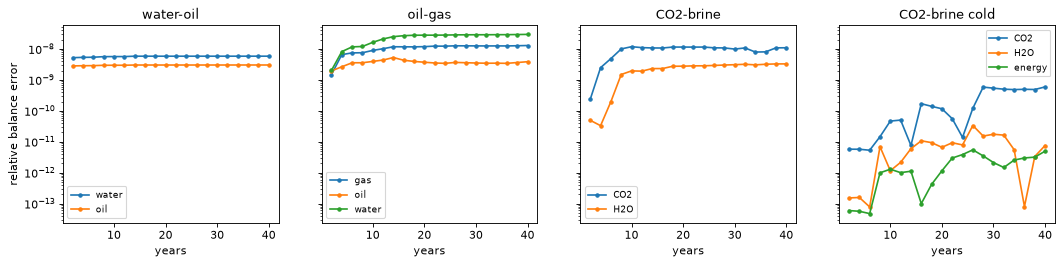

In [8]:
fig, ax = plt.subplots(1, 4, figsize=(16, 3.2), sharey=True)
for a, (name, err) in zip(ax, bal.items()):
    comps = comp_names(runs[name], err.shape[1])
    for i, c in enumerate(comps):
        a.semilogy(YEARS[1:], np.abs(err[1:, i]) + 1e-18, "o-", ms=3, label=c)
    a.set_title(name); a.set_xlabel("years"); a.legend(fontsize=8)
ax[0].set_ylabel("relative balance error")
save(fig, "fim12_mass_balance.png")

## Saturation maps
Injected-phase saturation after 40 years: top layer (map view) and the vertical section through INJ (row j = 5).

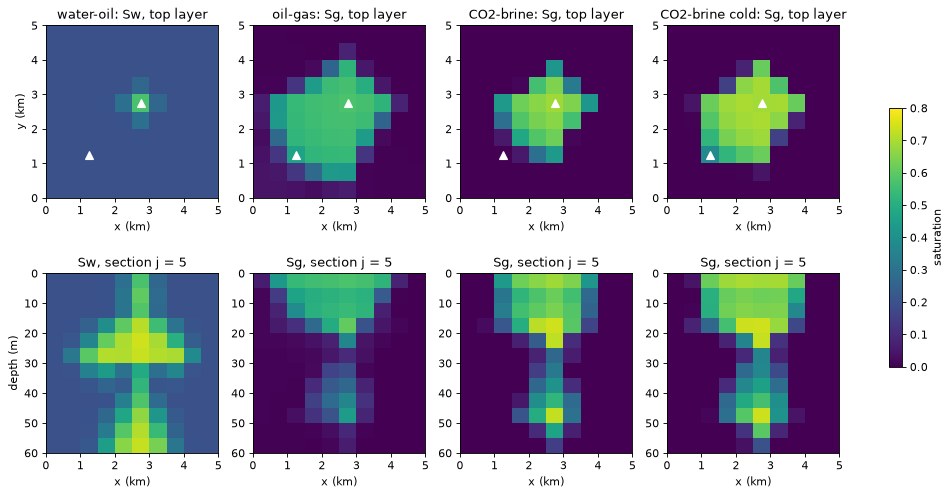

In [9]:
fig, ax = plt.subplots(2, 4, figsize=(16, 7), gridspec_kw={"hspace": 0.4})
ext_xy = [0, NX * cell[0] / 1e3, 0, NY * cell[1] / 1e3]
ext_xz = [0, NX * cell[0] / 1e3, NZ * cell[2], 0]
for c, (name, r) in enumerate(runs.items()):
    ph, lab = INJECTED[name]
    s = np.asarray(r["saturation"])[-1, :, ph].reshape(NZ, NY, NX)
    im = ax[0, c].imshow(s[0], origin="lower", extent=ext_xy, vmin=0, vmax=0.8, cmap="viridis")
    ax[0, c].plot([(INJ[0] + 0.5) * cell[0] / 1e3, (PROD[0] + 0.5) * cell[0] / 1e3],
                  [(INJ[1] + 0.5) * cell[1] / 1e3, (PROD[1] + 0.5) * cell[1] / 1e3], "w^", ms=7)
    ax[0, c].set_title(f"{name}: {lab}, top layer"); ax[0, c].set_xlabel("x (km)")
    ax[1, c].imshow(s[:, INJ[1], :], extent=ext_xz, vmin=0, vmax=0.8, cmap="viridis", aspect="auto")
    ax[1, c].set_title(f"{lab}, section j = {INJ[1]}"); ax[1, c].set_xlabel("x (km)")
ax[0, 0].set_ylabel("y (km)"); ax[1, 0].set_ylabel("depth (m)")
fig.colorbar(im, ax=ax, shrink=0.6, label="saturation")
save(fig, "fim12_saturation_maps.png")

cold CO2 case: minimum temperature 43.66 °C after 40 years


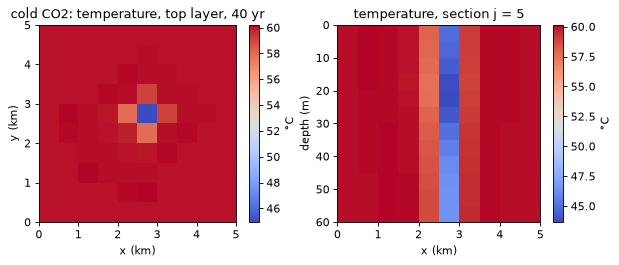

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(9, 3.2))
Tc = np.asarray(runs["CO2-brine cold"]["temperature"])[-1].reshape(NZ, NY, NX) - 273.15
im = ax[0].imshow(Tc[0], origin="lower", extent=ext_xy, cmap="coolwarm"); fig.colorbar(im, ax=ax[0], label="°C")
ax[0].set_title("cold CO2: temperature, top layer, 40 yr"); ax[0].set_xlabel("x (km)"); ax[0].set_ylabel("y (km)")
im = ax[1].imshow(Tc[:, INJ[1], :], extent=ext_xz, cmap="coolwarm", aspect="auto"); fig.colorbar(im, ax=ax[1], label="°C")
ax[1].set_title(f"temperature, section j = {INJ[1]}"); ax[1].set_xlabel("x (km)"); ax[1].set_ylabel("depth (m)")
print(f"cold CO2 case: minimum temperature {Tc.min():.2f} °C after 40 years")
save(fig, "fim12_temperature.png")

## Time series
Injected-phase pore volume in place (saturation × pore volume, summed), and well rates (kg/s per component;
positive is into the reservoir).

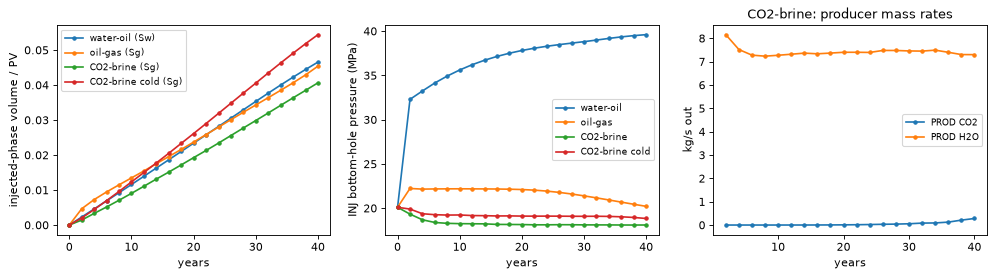

In [11]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.4))
for name, r in runs.items():
    ph, lab = INJECTED[name]
    s = np.asarray(r["saturation"])[:, :, ph]
    base = s[0]
    ax[0].plot(YEARS, ((s - base) * PV).sum(1) / PV.sum(), "o-", ms=3, label=f"{name} ({lab})")
    bhp = np.asarray(r["bhp"])
    ax[1].plot(YEARS, bhp[:, 0] / 1e6, "o-", ms=3, label=name)
ax[0].set_ylabel("injected-phase volume / PV"); ax[1].set_ylabel("INJ bottom-hole pressure (MPa)")
for a in ax[:2]:
    a.set_xlabel("years"); a.legend(fontsize=8)
r = runs["CO2-brine"]; q = np.asarray(r["well_mass_rate"])
for i, c in enumerate(r["component_names"]):
    ax[2].plot(YEARS[1:], -q[1:, 1, i], "o-", ms=3, label=f"PROD {c}")
ax[2].set_title("CO2-brine: producer mass rates"); ax[2].set_ylabel("kg/s out"); ax[2].set_xlabel("years"); ax[2].legend(fontsize=8)
save(fig, "fim12_time_series.png")

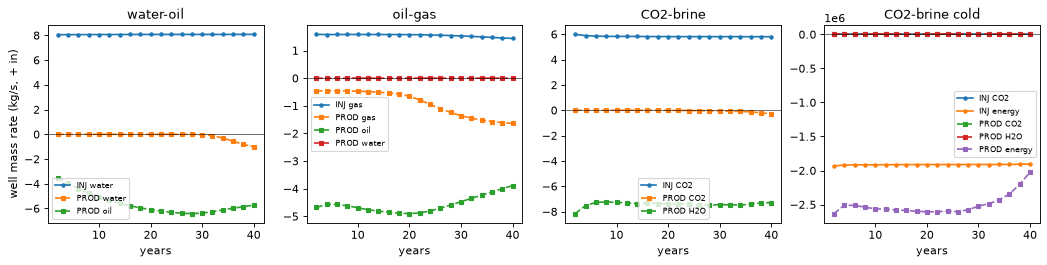

In [12]:
fig, ax = plt.subplots(1, 4, figsize=(16, 3.2))
for a, (name, r) in zip(ax, runs.items()):
    q = np.asarray(r["well_mass_rate"])
    for w, wn in enumerate(("INJ", "PROD")):
        for i, c in enumerate(r["component_names"]):
            if np.abs(q[1:, w, i]).max() > 1e-6:
                a.plot(YEARS[1:], q[1:, w, i], "o-" if w == 0 else "s--", ms=3, label=f"{wn} {c}")
    a.axhline(0, color="k", lw=0.5); a.set_title(name); a.set_xlabel("years"); a.legend(fontsize=7)
ax[0].set_ylabel("well mass rate (kg/s, + in)")
save(fig, "fim12_well_rates.png")

## Side-by-side comparison
Same grid, wells and reservoir injection rate. The plume extent is the number of cells with injected-phase
saturation above 0.05 (above the initial value for water).

water-oil        max Sw 0.742, plume cells 171, INJ BHP 39.60 MPa
oil-gas          max Sg 0.609, plume cells 185, INJ BHP 20.21 MPa
CO2-brine        max Sg 0.742, plume cells 135, INJ BHP 18.10 MPa
CO2-brine cold   max Sg 0.743, plume cells 161, INJ BHP 18.83 MPa


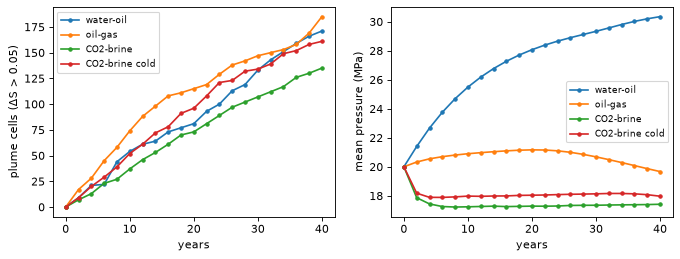

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
for name, r in runs.items():
    ph, lab = INJECTED[name]
    s = np.asarray(r["saturation"])[:, :, ph]
    ax[0].plot(YEARS, ((s - s[0]) > 0.05).sum(1), "o-", ms=3, label=name)
    p = np.asarray(r["p"])
    ax[1].plot(YEARS, (p * PV).sum(1) / PV.sum() / 1e6, "o-", ms=3, label=name)
ax[0].set_ylabel("plume cells (ΔS > 0.05)"); ax[1].set_ylabel("mean pressure (MPa)")
for a in ax:
    a.set_xlabel("years"); a.legend(fontsize=8)
save(fig, "fim12_comparison.png")
for name, r in runs.items():
    ph, lab = INJECTED[name]
    s = np.asarray(r["saturation"])[:, :, ph]
    print(f"{name:16s} max {lab} {s[-1].max():.3f}, plume cells {int(((s[-1] - s[0]) > 0.05).sum())}, "
          f"INJ BHP {np.asarray(r['bhp'])[-1, 0] / 1e6:.2f} MPa")

## 3D animations
One GIF per fluid system with the same grid, camera, colour scale and wells (vertical exaggeration 25).
Written to `SX_EXAMPLE_OUT`; the copies in `image/` of the repository come from this cell.

In [14]:
grid = RegularGrid(origin, cell, (NX, NY, NZ))
wl = [Well(nm, origin[0] + (ij[0] + 0.5) * cell[0], origin[1] + (ij[1] + 0.5) * cell[1], 0.0, NZ * cell[2], col)
      for nm, ij, col in (("INJ", INJ, "#1f4e9c"), ("PROD", PROD, "#b2182b"))]
for name, fn, title in (("water-oil", "fim_water_oil.gif", "Water injection into dead oil"),
                        ("oil-gas", "fim_oil_gas.gif", "Gas injection into black oil"),
                        ("CO2-brine", "fim_co2_brine.gif", "CO2 injection into brine")):
    ph, lab = INJECTED[name]
    frames = np.asarray(runs[name]["saturation"])[:, :, ph]
    animate_grid(grid, frames, OUT / fn, times=YEARS, wells=wl, label=lab, units="", clim=(0.0, 0.8),
                 cmap="viridis", z_exaggeration=25.0, title=title, time_label="{:.0f} years",
                 fps=5, width=720, height=500, hold_last=5, bar_fmt="%.1f")
    print(fn, f"{(OUT / fn).stat().st_size / 1e6:.2f} MB")

2026-10-31 13:38:26.181 (   1.125s) [    7F46294E3780]vtkXOpenGLRenderWindow.:1452  WARN| bad X server connection. DISPLAY=


fim_water_oil.gif 1.15 MB


fim_oil_gas.gif 1.18 MB


fim_co2_brine.gif 1.19 MB


## Results summary
The table below is built by the next cell from the run results above (nothing is typed in by hand). Balance
error is the worst relative mass (and, for the cold case, energy) balance error over all report times.
CO2 breakthrough is the first report time at which PROD produces CO2 at more than 1 % of the injected CO2
mass rate.

In [15]:
def breakthrough(r, frac=0.01):
    q = np.asarray(r["well_mass_rate"]); ic = list(r["component_names"]).index("CO2")
    hit = np.nonzero(-q[1:, 1, ic] > frac * q[1:, 0, ic])[0]
    return f"{YEARS[1:][hit[0]]:.0f} yr" if hit.size else "not by 40 yr"
rows = ["| Case | Run time | Steps / cuts / Newton | Worst balance error | Max injected saturation | INJ pressure at 40 yr | CO2 breakthrough | Min temperature |",
        "|---|---|---|---|---|---|---|---|"]
for name, r in runs.items():
    ph, lab = INJECTED[name]
    s = np.asarray(r["saturation"])[:, :, ph]
    bt = breakthrough(r) if "CO2" in name else "–"
    tmin = f"{np.asarray(r['temperature']).min() - 273.15:.2f} °C" if name == "CO2-brine cold" else "–"
    rows.append(f"| {name} | {RUNTIME[name]:.0f} s | {r['n_steps']} / {r['n_cuts']} / {r['n_newton']} | "
                f"{np.abs(bal[name]).max():.1e} | {lab} {s[-1].max():.2f} | {np.asarray(r['bhp'])[-1, 0] / 1e6:.2f} MPa | "
                f"{bt} | {tmin} |")
display(Markdown("\n".join(rows)))

| Case | Run time | Steps / cuts / Newton | Worst balance error | Max injected saturation | INJ pressure at 40 yr | CO2 breakthrough | Min temperature |
|---|---|---|---|---|---|---|---|
| water-oil | 8 s | 170 / 0 / 515 | 5.9e-09 | Sw 0.74 | 39.60 MPa | – | – |
| oil-gas | 27 s | 170 / 0 / 540 | 3.0e-08 | Sg 0.61 | 20.21 MPa | – | – |
| CO2-brine | 19 s | 170 / 0 / 552 | 1.2e-08 | Sg 0.74 | 18.10 MPa | 32 yr | – |
| CO2-brine cold | 38 s | 170 / 0 / 618 | 5.9e-10 | Sg 0.74 | 18.83 MPa | 24 yr | 43.66 °C |

## Limitations
- Low injection rate: with unit permeabilities of 0.5–80 mD and an OBL table limited to 50 MPa, injection is
  kept at 0.008 m³/s, so only about 5 % of the pore volume is injected in 40 years and the plumes stay within
  a few cells of INJ.
- The black-oil PVT table is synthetic (same shape as the unit tests), not a measured fluid.
- CO2–brine uses a salt-free mass basis (NaCl is fixed in the brine), with no salt precipitation and constant
  Corey relative permeability without hysteresis.
- The oil–gas plume cell count includes gas that comes out of solution near PROD, not only injected gas.
- The cold-CO2 case is shown as temperature maps only; there is no GIF for it.
- Experimental solver: not validated as equivalent to open-DARTS or OpenGeoSys.